In [63]:
import pandas as pd
from pathlib import Path
import matplotlib as plt

DATA_DIR = Path("..") / "data"
PROCESSED_DIR = DATA_DIR / "processed"

In [6]:
data = pd.read_parquet(PROCESSED_DIR / "merged.parquet")
data.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [8]:
data.shape
data.dtypes.value_counts()

float32     399
category     12
int64         4
category      4
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
Name: count, dtype: int64

In [51]:
data["isFraud"].mean()

np.float64(0.03499000914417313)

In [24]:
data.isna().astype('int').sum().sort_values(ascending=False).head(5)/len(data)


id_24    0.991962
id_25    0.991310
id_07    0.991271
id_08    0.991271
id_21    0.991264
dtype: float64

In [26]:
identity_ids = pd.read_csv(DATA_DIR / "train_identity.csv", usecols = ["TransactionID"])
data["has_identity"] = data["TransactionID"].isin(identity_ids["TransactionID"])

In [28]:
data["has_identity"]

0         False
1         False
2         False
3         False
4          True
          ...  
590535    False
590536    False
590537    False
590538    False
590539    False
Name: has_identity, Length: 590540, dtype: bool

In [34]:
data.groupby("has_identity")["isFraud"].mean()

has_identity
False    0.020939
True     0.078470
Name: isFraud, dtype: float64

In [38]:
data.groupby("has_identity")["isFraud"].value_counts()

has_identity  isFraud
False         0          436962
              1            9345
True          0          132915
              1           11318
Name: count, dtype: int64

In [44]:
data["has_identity"].astype('int8')

0         0
1         0
2         0
3         0
4         1
         ..
590535    0
590536    0
590537    0
590538    0
590539    0
Name: has_identity, Length: 590540, dtype: int8

In [45]:
data.to_parquet(PROCESSED_DIR / "merged.parquet")

In [53]:
data.groupby("ProductCD")["isFraud"].mean().sort_values()

C:\Users\samib\AppData\Local\Temp\ipykernel_18696\2246162663.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("ProductCD")["isFraud"].mean().sort_values()


ProductCD
W    0.020399
R    0.037826
H    0.047662
S    0.058996
C    0.116873
Name: isFraud, dtype: float64

In [54]:
data.groupby("ProductCD")["isFraud"].agg(["mean", "count", "sum"])

C:\Users\samib\AppData\Local\Temp\ipykernel_18696\3110046652.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("ProductCD")["isFraud"].agg(["mean", "count", "sum"])


,mean,count,sum
ProductCD,,,
C,0.116873,68519,8008
H,0.047662,33024,1574
R,0.037826,37699,1426
S,0.058996,11628,686
W,0.020399,439670,8969


In [55]:
pd.crosstab(data["ProductCD"], data["has_identity"], normalize="index")

has_identity,False,True
ProductCD,,
C,0.092339,0.907661
H,0.003513,0.996487
R,0.004005,0.995995
S,0.003698,0.996302
W,1.000000,0.000000


In [59]:
data["TransactionDT"].max()
data["day"] = data["TransactionDT"] // 86400
data["hour"] = (data["TransactionDT"] // 3600) % 24

<Axes: xlabel='day'>

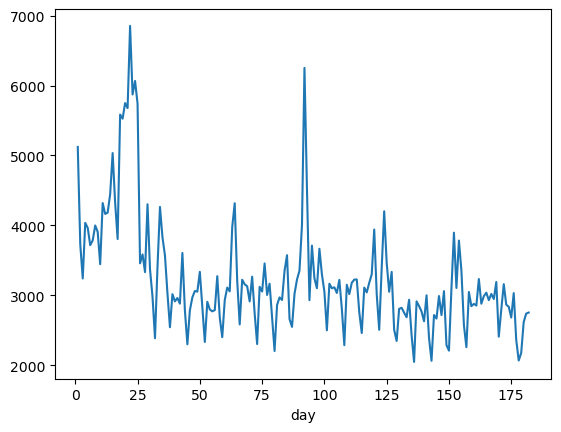

In [68]:
daily = data.groupby("day")["isFraud"].agg(["count", "mean"])
daily["count"].plot()

<Axes: xlabel='day'>

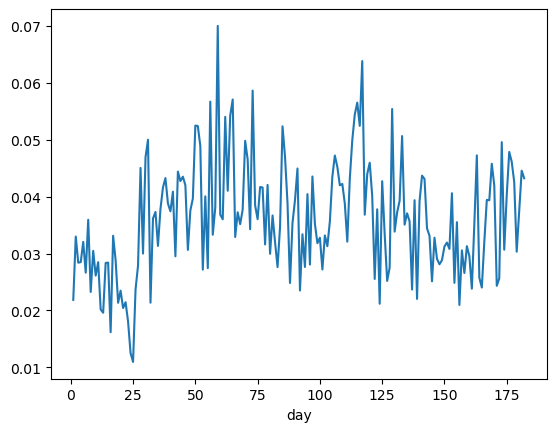

In [69]:
daily["mean"].plot()

<Axes: xlabel='hour'>

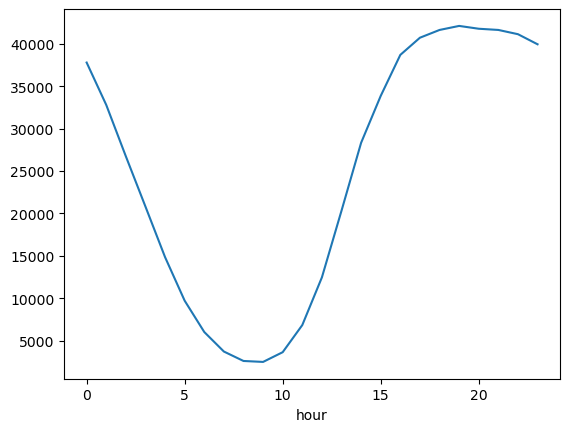

In [91]:
hourly = data.groupby("hour")['isFraud'].agg(["mean","count", "sum"])
hourly['count'].plot()

<Axes: xlabel='hour'>

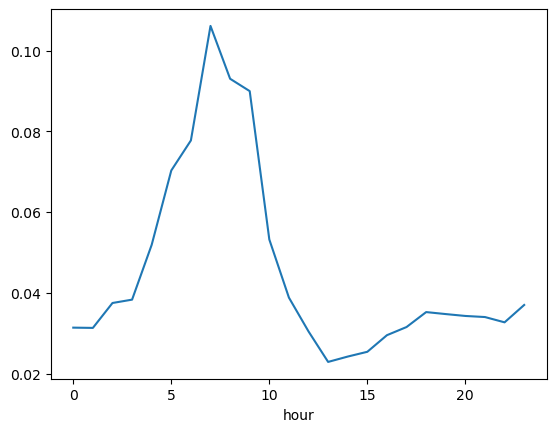

In [89]:
hourly["mean"].plot()

Expected plots, when the number of transactions drop, the fraction of transactions being fraudlent increases (peaks just before the lowest num of transactions) this is likely due to the number of fraudulent transactions not dropping as much as legitimate during more quiet hours potentially due to differnt timezones and automation. This indicates hour 5-10 are late hours.

<Axes: xlabel='hour'>

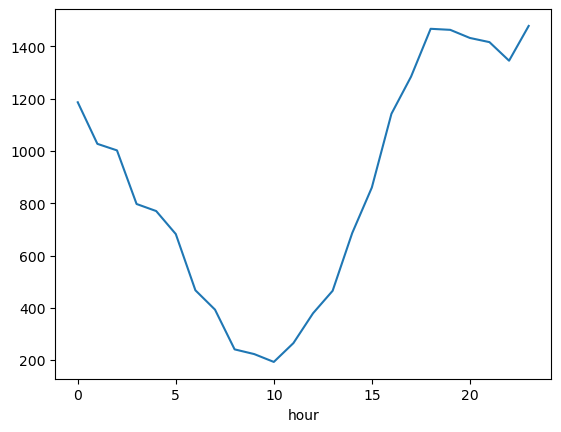

In [92]:
hourly['sum'].plot()

In [100]:
data["hour"] = pd.to_numeric(data["hour"], downcast="integer")
data["day"] = pd.to_numeric(data["day"], downcast="integer")
data["has_identity"] = data["has_identity"].astype("int8")
data["has_identity"] = pd.to_numeric(data["has_identity"], downcast="integer")

In [101]:
data[["day", "hour", "has_identity"]].dtypes

day             int16
hour             int8
has_identity     int8
dtype: object

In [102]:
data.to_parquet(PROCESSED_DIR / "merged.parquet")

In [103]:
data = pd.read_parquet(PROCESSED_DIR / "merged.parquet")

In [104]:
data.shape

(590540, 437)